# Exercise 64 – Solving a first-order ODE with a neural network

**Week 14 · Physics-informed neural networks**

Instead of fitting data, a *physics-informed* neural network (PINN) is
trained so that it satisfies a differential equation. For

$$\frac{dy}{dx} = 0.9\cos(x)\,y^2, \qquad y(x_0) = y_0$$

the loss has two parts:

$$\mathcal{L} = \big(y_\text{NN}(x_0) - y_0\big)^2
  + \frac{1}{M}\sum_{m=1}^{M}\Big(y_\text{NN}'(x_m) - 0.9\cos(x_m)\,y_\text{NN}(x_m)^2\Big)^2$$

where $x_m$ are random *collocation points* redrawn every step and
$y'_\text{NN}$ comes from autograd. The analytic solution is

$$y(x) = \frac{10\,y_0}{10 - 9y_0\,(\sin x - \sin x_0)}.$$

### Lecture example: Newton's law of cooling
A cup of coffee cooling towards room temperature obeys
$dT/dt = -r\,(T - T_\text{env})$; the same recipe applies, and an unknown
cooling rate $r$ can even be learned as an extra `nn.Parameter`.

In [1]:
import matplotlib.pyplot as plt
import torch

from comphy.pinn import PINN, train_pinn

torch.manual_seed(0)


def residual(x, y, dydx):
    return dydx - 0.9 * torch.cos(x) * y**2


def analytic(x, x0, y0):
    return 10 * y0 / (10 - 9 * y0 * (torch.sin(x) - torch.sin(torch.tensor(x0))))


xs = torch.linspace(0, 10, 300).view(-1, 1)

## Initial condition $y(0) = 1$
How the solution develops with the number of training epochs:

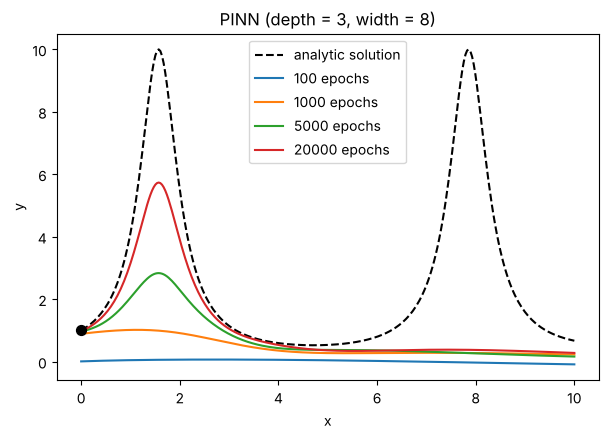

In [2]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(xs, analytic(xs, 0.0, 1.0), "k--", label="analytic solution")
ax.scatter([0], [1], color="black", s=50, zorder=3)
for epochs in [100, 1000, 5000, 20000]:
    torch.manual_seed(0)
    model = PINN(depth=3, width=8)
    train_pinn(model, residual, x_range=(0, 10), epochs=epochs, values=[(0.0, 1.0)])
    with torch.no_grad():
        ax.plot(xs, model(xs), label=f"{epochs} epochs")
ax.set(xlabel="x", ylabel="y", title=f"PINN ({model.describe()})")
ax.legend()
plt.show()

With more training the network follows the first peak better and better,
but even after 20 000 epochs it misses the second peak. Far from $x_0$ a small,
almost constant $y$ nearly satisfies the equation (the right-hand side is
proportional to $y^2$), so the residual loss gives little push towards the
true solution there.

## Adding more points on the solution
The solution passes through $y = 5$ at four points,
$x \approx 1.095,\ 2.047,\ 7.378,\ 8.330$. Using only the first one as a
condition repeats the problem above.

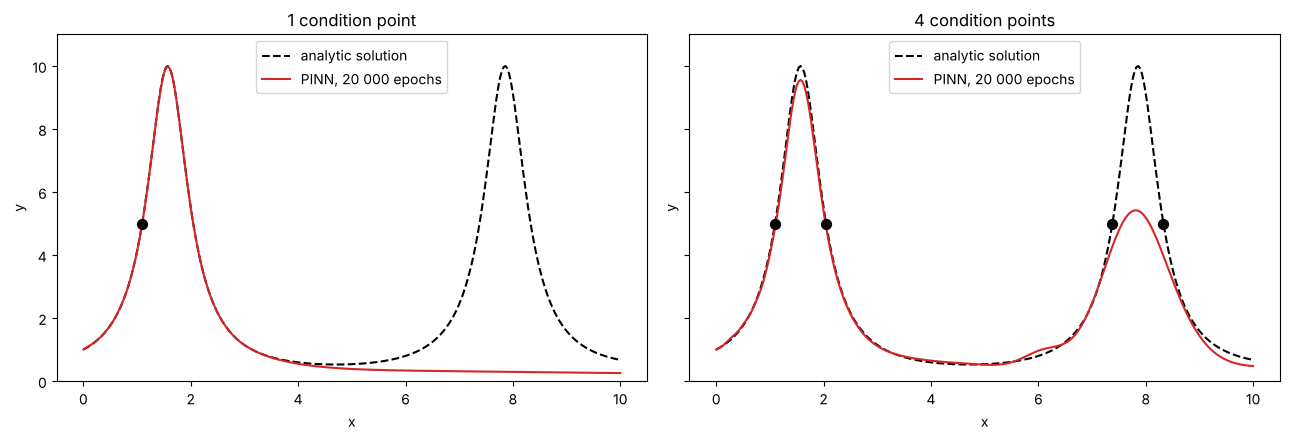

In [3]:
x_points = [1.09491408, 2.04667858, 7.37809938, 8.32986388]
y_value = 5.0

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, points in zip(axes, [x_points[:1], x_points]):
    torch.manual_seed(0)
    model = PINN(depth=3, width=8)
    train_pinn(model, residual, x_range=(0, 10), epochs=20_000,
               values=[(x, y_value) for x in points])
    ax.plot(xs, analytic(xs, x_points[0], y_value), "k--", label="analytic solution")
    ax.scatter(points, [y_value] * len(points), color="black", s=50, zorder=3)
    with torch.no_grad():
        ax.plot(xs, model(xs), color="C3", label="PINN, 20 000 epochs")
    ax.set(xlabel="x", ylabel="y", ylim=(0, 11),
           title=f"{len(points)} condition point{'s' if len(points) > 1 else ''}")
    ax.legend(loc="upper center")
fig.tight_layout()
plt.show()

With the extra points near $x \approx 8$ the network is forced to leave the
flat branch, and it finds the second peak as well – although after 20 000
epochs it does not yet reach the full height.